## carregando o csv local

usamos o arquivo em `data/raw` para a análise. os nomes de colunas com espaço duplo são normalizados.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

FIG_DIR = '../data/results/hypotesis-conclusions'
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv('../data/raw/raw-customer-churn.csv')
df.columns = df.columns.str.replace(r'\s+', ' ', regex=True).str.strip()
print(df.shape)
df.head()

(3150, 14)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call Failure             3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription Length      3150 non-null   int64  
 3   Charge Amount            3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

## distribuição das classes

,contagem,proporção
Churn,,
0,2655,0.8429
1,495,0.1571


razão de desbalanceamento (não churn : churn) = 5.36 : 1


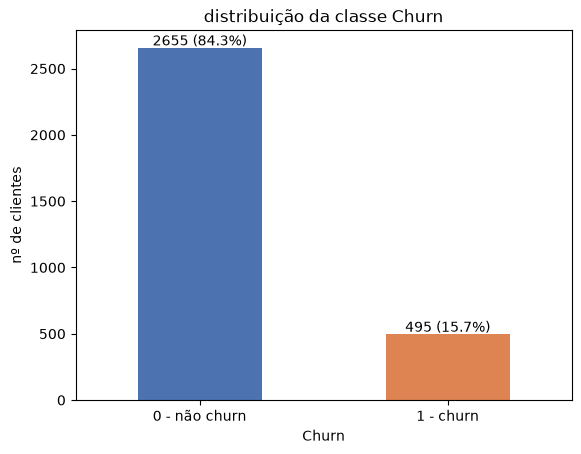

In [3]:
contagem = df['Churn'].value_counts()
proporcao = df['Churn'].value_counts(normalize=True).round(4)
display(pd.DataFrame({'contagem': contagem, 'proporção': proporcao}))
print(f"razão de desbalanceamento (não churn : churn) = {contagem[0]/contagem[1]:.2f} : 1")

ax = contagem.plot(kind='bar', color=['#4C72B0', '#DD8452'])
ax.set_xticklabels(['0 - não churn', '1 - churn'], rotation=0)
ax.set_ylabel('nº de clientes'); ax.set_title('distribuição da classe Churn')
for i, v in enumerate(contagem): ax.text(i, v + 20, f'{v} ({proporcao.iloc[i]:.1%})', ha='center')
plt.savefig(f'{FIG_DIR}/eda-distribuicao-classes.png', dpi=150, bbox_inches='tight'); plt.show()

a base é **desbalanceada**: 2655 clientes não churn (84,3%) contra 495 churn (15,7%), uma razão de 5,36 : 1. um classificador que sempre responde "não churn" já chega a ~84% de acurácia sem identificar nenhum churn, por isso a **acurácia não será usada** como métrica.

## valores ausentes

In [4]:
print('total de valores ausentes:', df.isna().sum().sum())
df.isna().sum()

total de valores ausentes: 0


Call Failure               0
Complains                  0
Subscription Length        0
Charge Amount              0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

## duplicatas

In [5]:
dup = df.duplicated()
print('linhas exatamente duplicadas:', dup.sum())
df_unico = df.drop_duplicates()
print('linhas únicas:', len(df_unico))
print('distribuição da classe após remover duplicatas:')
display(df_unico['Churn'].value_counts(normalize=True).round(4))

# mesmas features, rótulos diferentes (ruído de rótulo)
feats = [c for c in df.columns if c != 'Churn']
conflito = df_unico.groupby(feats)['Churn'].nunique()
print('combinações de features com rótulos conflitantes:', (conflito > 1).sum())

linhas exatamente duplicadas: 300
linhas únicas: 2850
distribuição da classe após remover duplicatas:


Churn
0    0.8435
1    0.1565
Name: proportion, dtype: float64

combinações de features com rótulos conflitantes: 14


- 300 linhas são cópias exatas; sobram 2850 linhas únicas.
- a proporção de churn quase não muda depois da remoção (15,71% → 15,65%), então remover as duplicatas não distorce a classe. **decisão: remover as duplicatas**, o que também evita que a mesma linha caia no treino e no teste de um mesmo fold.
- 14 combinações de atributos aparecem com rótulo 0 **e** 1. é ruído de rótulo que nenhum modelo consegue acertar por completo; essas linhas ficam na base.

## estatísticas descritivas

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Call Failure,3150.0,7.627937,7.263886,0.0,1.00000,6.00,12.00000,36.00
Complains,3150.0,0.076508,0.265851,0.0,0.00000,0.00,0.00000,1.00
Subscription Length,3150.0,32.541905,8.573482,3.0,30.00000,35.00,38.00000,47.00
Charge Amount,3150.0,0.942857,1.521072,0.0,0.00000,0.00,1.00000,10.00
Seconds of Use,3150.0,4472.459683,4197.908687,0.0,1391.25000,2990.00,6478.25000,17090.00
Frequency of use,3150.0,69.460635,57.413308,0.0,27.00000,54.00,95.00000,255.00
Frequency of SMS,3150.0,73.174921,112.237560,0.0,6.00000,21.00,87.00000,522.00
Distinct Called Numbers,3150.0,23.509841,17.217337,0.0,10.00000,21.00,34.00000,97.00
Age Group,3150.0,2.826032,0.892555,1.0,2.00000,3.00,3.00000,5.00
Tariff Plan,3150.0,1.077778,0.267864,1.0,1.00000,1.00,1.00000,2.00


## possíveis inconsistências

In [7]:
print('Age x Age Group (correspondência 1:1?)')
display(pd.crosstab(df['Age'], df['Age Group']))

print('clientes sem nenhum uso (Frequency of use = 0):', (df['Frequency of use'] == 0).sum())
print('  desses, com Seconds of Use = 0:', ((df['Frequency of use'] == 0) & (df['Seconds of Use'] == 0)).sum())
print('números distintos > total de ligações:', (df['Distinct Called Numbers'] > df['Frequency of use']).sum())
print('falhas > total de ligações:', (df['Call Failure'] > df['Frequency of use']).sum())

Age x Age Group (correspondência 1:1?)


Age Group,1,2,3,4,5
Age,,,,,
15,123,0,0,0,0
25,0,1037,0,0,0
30,0,0,1425,0,0
45,0,0,0,395,0
55,0,0,0,0,170


clientes sem nenhum uso (Frequency of use = 0): 154
  desses, com Seconds of Use = 0: 154
números distintos > total de ligações: 120
falhas > total de ligações: 3


- `Age` e `Age Group` têm correspondência 1:1 (tabela acima). **decisão: remover `Age Group`** e manter `Age`.
- `Charge Amount` = 10 em 7 linhas, embora a documentação indique 0-9. **decisão: tratar como valor válido** (é a faixa mais alta de cobrança, e nenhum desses clientes deu churn, igual às faixas 5-9).
- 154 clientes (107 após remover duplicatas) não têm nenhum uso: ligações e segundos são zero ao mesmo tempo, o que é coerente. **decisão: manter**, pois um cliente pode nunca usar o serviço e continuar na empresa (ou sair dela), e isso é informação sobre churn.
- 120 linhas têm mais números distintos chamados do que ligações feitas, e 3 linhas têm mais falhas do que ligações. **decisão: manter**. esses valores não são necessariamente inválidos (por exemplo, a contagem pode incluir ligações recebidas ou tentativas), mas indicam **ruído na medição** desses atributos, o que precisa ser declarado no relatório.

## atributos binários/ordinais x churn

In [8]:
for col in ['Status', 'Complains', 'Tariff Plan', 'Age Group', 'Charge Amount']:
    t = pd.crosstab(df[col], df['Churn'], margins=True)
    t['% churn'] = (t[1] / t['All'] * 100).round(1)
    print(f'--- {col}'); display(t)

--- Status


Churn,0,1,All,% churn
Status,,,,
1,2243,125,2368,5.3
2,412,370,782,47.3
All,2655,495,3150,15.7


--- Complains


Churn,0,1,All,% churn
Complains,,,,
0,2614,295,2909,10.1
1,41,200,241,83.0
All,2655,495,3150,15.7


--- Tariff Plan


Churn,0,1,All,% churn
Tariff Plan,,,,
1,2416,489,2905,16.8
2,239,6,245,2.4
All,2655,495,3150,15.7


--- Age Group


Churn,0,1,All,% churn
Age Group,,,,
1,123,0,123,0.0
2,853,184,1037,17.7
3,1195,230,1425,16.1
4,316,79,395,20.0
5,168,2,170,1.2
All,2655,495,3150,15.7


--- Charge Amount


Churn,0,1,All,% churn
Charge Amount,,,,
0,1347,421,1768,23.8
1,574,43,617,7.0
2,372,23,395,5.8
3,192,7,199,3.5
4,75,1,76,1.3
5,30,0,30,0.0
6,11,0,11,0.0
7,14,0,14,0.0
8,19,0,19,0.0


- **Status**: 47,3% de churn entre inativos contra 5,3% entre ativos. como o status é medido na mesma janela dos dados de uso, é forte candidato a **vazamento de informação (leak)**. **decisão: rodar os experimentos com e sem `Status`** e comparar.
- **Complains**: 83,0% de churn entre quem reclamou contra 10,1% entre quem não reclamou (ver H2).
- **Tariff Plan**: só 245 clientes contratuais, dos quais 6 deram churn (2,4%), contra 16,8% no pré-pago (ver H5).
- **Age Group**: as faixas extremas quase não têm churn (0% no grupo 1, 1,2% no grupo 5), enquanto os grupos 2-4 ficam entre 16% e 20%. a relação com a idade não é linear.
- **Charge Amount**: o churn cai conforme a faixa de cobrança sobe (23,8% na faixa 0, 7,0% na faixa 1) e é zero a partir da faixa 5.

## atributos numéricos: distribuição e outliers

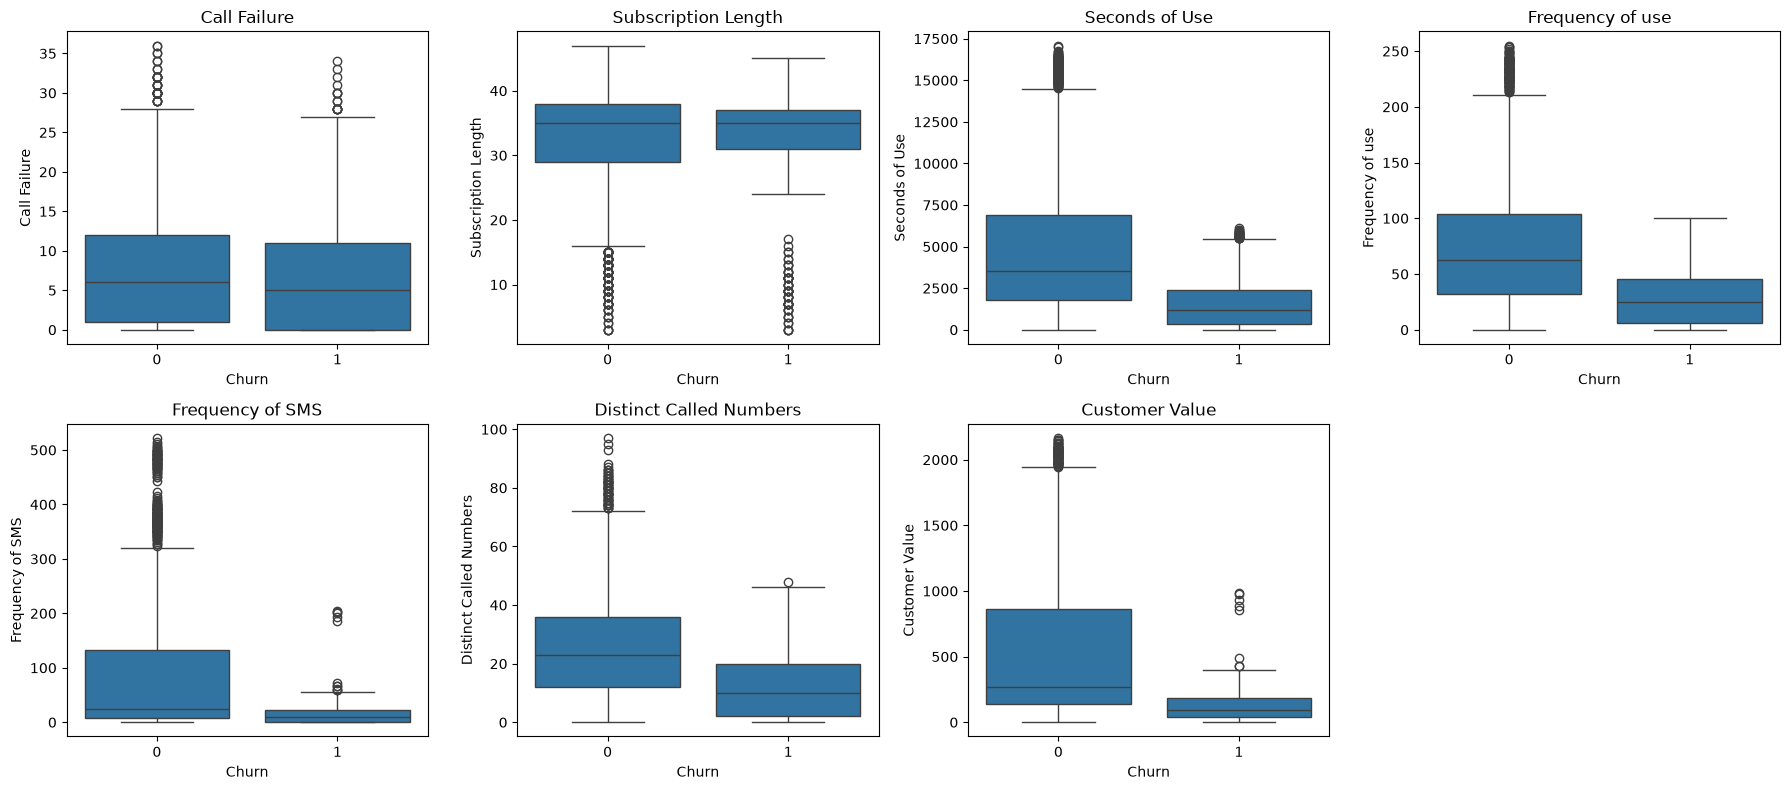

assimetria (skew):


Call Failure               1.09
Subscription Length       -1.30
Seconds of Use             1.32
Frequency of use           1.14
Frequency of SMS           1.97
Distinct Called Numbers    1.03
Customer Value             1.43
dtype: float64

In [9]:
num = ['Call Failure', 'Subscription Length', 'Seconds of Use', 'Frequency of use',
       'Frequency of SMS', 'Distinct Called Numbers', 'Customer Value']
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, c in zip(axes, num):
    sns.boxplot(data=df, x='Churn', y=c, ax=ax); ax.set_title(c)
axes[-1].axis('off'); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/eda-boxplots-atributos-numericos.png', dpi=150, bbox_inches='tight'); plt.show()

print('assimetria (skew):'); display(df[num].skew().round(2))

- as escalas são muito diferentes: segundos de uso chegam a 17.090, enquanto falhas chegam a 36.
- quase todos os atributos de uso têm assimetria positiva, com cauda longa à direita: SMS (1,97), Customer Value (1,43), Seconds of Use (1,32). `Subscription Length` é o único com assimetria negativa (-1,30): a maioria dos clientes tem muito tempo de casa.
- nos boxplots, quem dá churn tem uso visivelmente menor (ver H6).
- impacto nos algoritmos escolhidos: o **MLP** é sensível à escala e precisa de **padronização**; a **regressão logística** também se beneficia dela (convergência e regularização comparáveis entre atributos). o **XGBoost**, baseado em árvores, não precisa. o **Naive Bayes gaussiano** supõe distribuição normal por classe, o que a assimetria viola.

## correlação

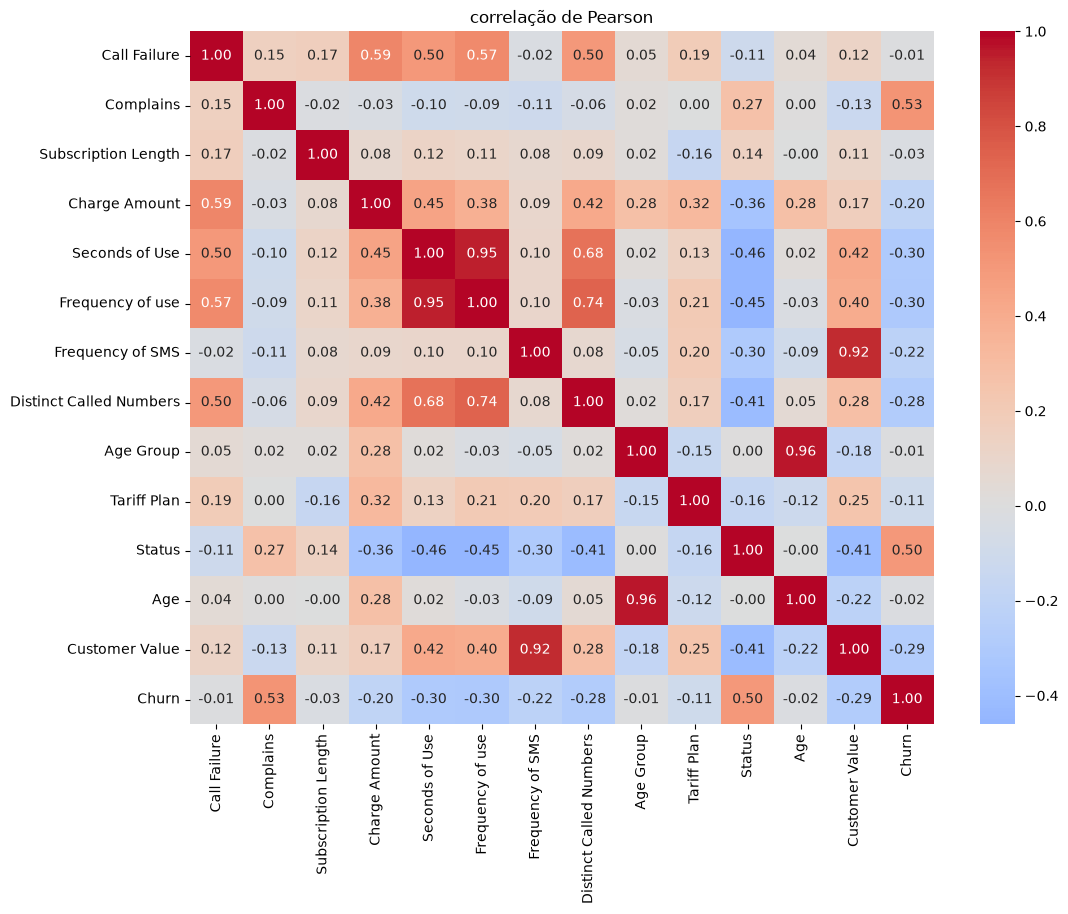

pares com |r| > 0.8:


Age Group         Age                 0.960758
Seconds of Use    Frequency of use    0.946489
Frequency of SMS  Customer Value      0.924877
dtype: float64

correlação com Churn:


Frequency of use          -0.303337
Seconds of Use            -0.298935
Customer Value            -0.289144
Distinct Called Numbers   -0.278867
Frequency of SMS          -0.220754
Charge Amount             -0.202305
Tariff Plan               -0.105853
Subscription Length       -0.032588
Age                       -0.017705
Age Group                 -0.014550
Call Failure              -0.008987
Status                     0.498976
Complains                  0.532053
Name: Churn, dtype: float64

In [10]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('correlação de Pearson'); plt.savefig(f'{FIG_DIR}/eda-correlacao.png', dpi=150, bbox_inches='tight'); plt.show()

corr = df.corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print('pares com |r| > 0.8:'); display(pares[pares > 0.8].sort_values(ascending=False))
print('correlação com Churn:'); display(df.corr()['Churn'].drop('Churn').sort_values())

pares com |r| > 0,8:
- `Age` × `Age Group` (0,96): redundância já tratada com a remoção de `Age Group`.
- `Seconds of Use` × `Frequency of use` (0,95): quem liga mais, fala mais tempo.
- `Frequency of SMS` × `Customer Value` (0,92): o valor do cliente parece ser calculado principalmente a partir do uso de SMS.

correlação com churn: os mais fortes são `Complains` (+0,53) e `Status` (+0,50); em seguida vêm os atributos de uso, todos negativos (entre -0,22 e -0,30), ou seja, quem usa menos tende a sair. `Call Failure` sozinho praticamente não se correlaciona com churn (-0,01; ver H3/H4).

a redundância entre atributos de uso viola a hipótese de independência do **Naive Bayes** e pode deixar instáveis os coeficientes da **regressão logística** (a regularização ajuda nisso). isso deve ser considerado na interpretação dos resultados.

# hipóteses

daqui em diante a análise usa a base **sem duplicatas** (`dfu`, 2850 linhas), que é a que será usada nos experimentos.

In [11]:
dfu = df.drop_duplicates().reset_index(drop=True)
os.makedirs('../data/processed', exist_ok=True)
dfu.to_csv('../data/processed/customer-churn-sem-duplicatas.csv', index=False)

def taxa_churn(d, por):
    t = d.groupby(por, observed=True)['Churn'].agg(['count', 'mean'])
    t.columns = ['n', '% churn']; t['% churn'] = (t['% churn'] * 100).round(1)
    return t

## H1: há alguma feature singular decisiva para o churn?

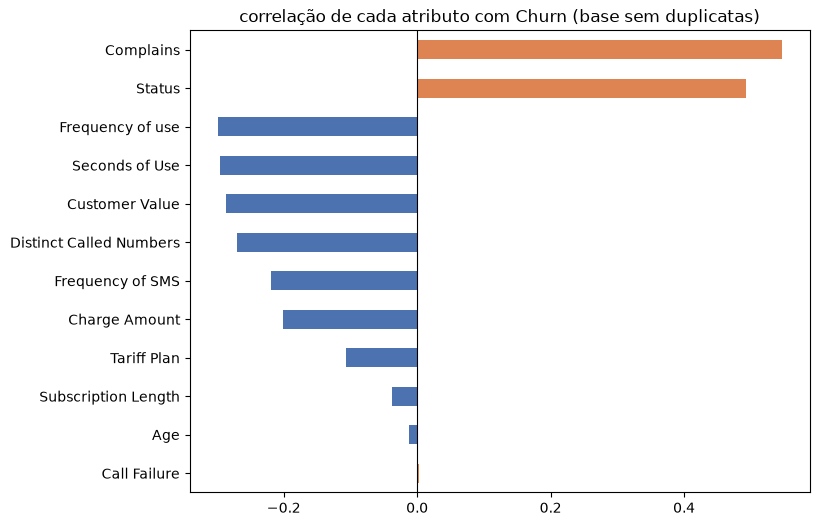

regra "Complains == 1 -> churn": recall = 0.426, especificidade = 0.983
regra "Status == 2 -> churn": recall = 0.729, especificidade = 0.851


In [12]:
feats = [c for c in dfu.columns if c not in ('Churn', 'Age Group')]
corr_churn = dfu[feats].corrwith(dfu['Churn']).sort_values(key=abs)

fig, ax = plt.subplots(figsize=(8, 6))
corr_churn.plot(kind='barh', ax=ax, color=['#DD8452' if v > 0 else '#4C72B0' for v in corr_churn])
ax.axvline(0, color='k', lw=0.8); ax.set_title('correlação de cada atributo com Churn (base sem duplicatas)')
plt.savefig(f'{FIG_DIR}/H1-correlacao-com-churn.png', dpi=150, bbox_inches='tight'); plt.show()

# quão bem cada binário separa sozinho: recall e especificidade da regra "atributo indica churn"
for col, val in [('Complains', 1), ('Status', 2)]:
    pred = (dfu[col] == val).astype(int)
    rec = (pred[dfu.Churn == 1] == 1).mean(); esp = (pred[dfu.Churn == 0] == 0).mean()
    print(f'regra "{col} == {val} -> churn": recall = {rec:.3f}, especificidade = {esp:.3f}')

**conclusão H1**: nenhum atributo sozinho decide o churn. `Complains` e `Status` são os mais fortes (r ≈ 0,5), mas, usados como regra única, deixam escapar boa parte dos churns:
- "reclamou → churn": recall de 0,426 e especificidade de 0,983. quase todo cliente que reclama sai, mas a maioria dos que saem (57%) nunca reclamou.
- "inativo → churn": recall de 0,729 e especificidade de 0,851. captura mais churns, mas ainda deixa escapar 27% deles e erra 15% dos clientes que ficam, além de ser suspeito de vazamento.

o churn parece resultar da combinação de reclamação, status e baixo uso, o que justifica usar classificadores multivariados. essas regras simples também servem de referência mínima: um modelo que não supere o recall de 0,73 da regra do `Status` acrescenta pouco.

## H2: o quanto ter reclamado influencia o churn?

,n,% churn
Complains,,
0,2620,9.8
1,230,82.6


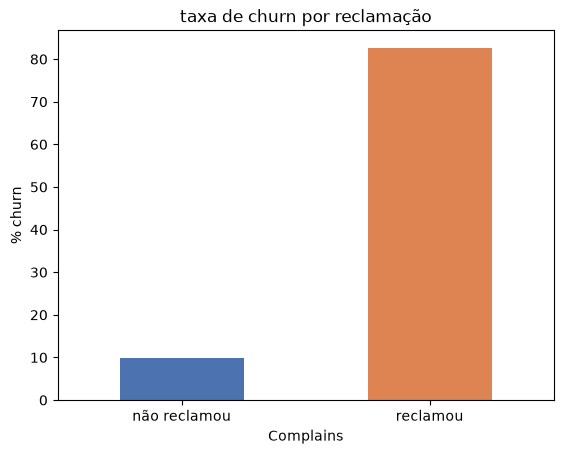

reclamação x status:


n  % churn
Complains Status               
0         1       2085      3.1
          2        535     35.9
1         1         81     70.4
          2        149     89.3

In [13]:
t = taxa_churn(dfu, 'Complains'); display(t)
ax = t['% churn'].plot(kind='bar', color=['#4C72B0', '#DD8452'])
ax.set_xticklabels(['não reclamou', 'reclamou'], rotation=0); ax.set_ylabel('% churn')
ax.set_title('taxa de churn por reclamação'); plt.savefig(f'{FIG_DIR}/H2-churn-por-reclamacao.png', dpi=150, bbox_inches='tight'); plt.show()

print('reclamação x status:'); display(taxa_churn(dfu, ['Complains', 'Status']))

**conclusão H2**: reclamar multiplica o risco de churn por cerca de 8 (82,6% contra 9,8%). mesmo entre clientes **ativos**, quem reclamou sai em 70,4% dos casos, contra 3,1% de quem não reclamou. a reclamação é o sinal mais forte da base e não depende só do `Status`. para a empresa, isso aponta para o atendimento pós-reclamação como ponto de retenção.

## H3: há relação entre o número de ligações falhadas e a reclamação?

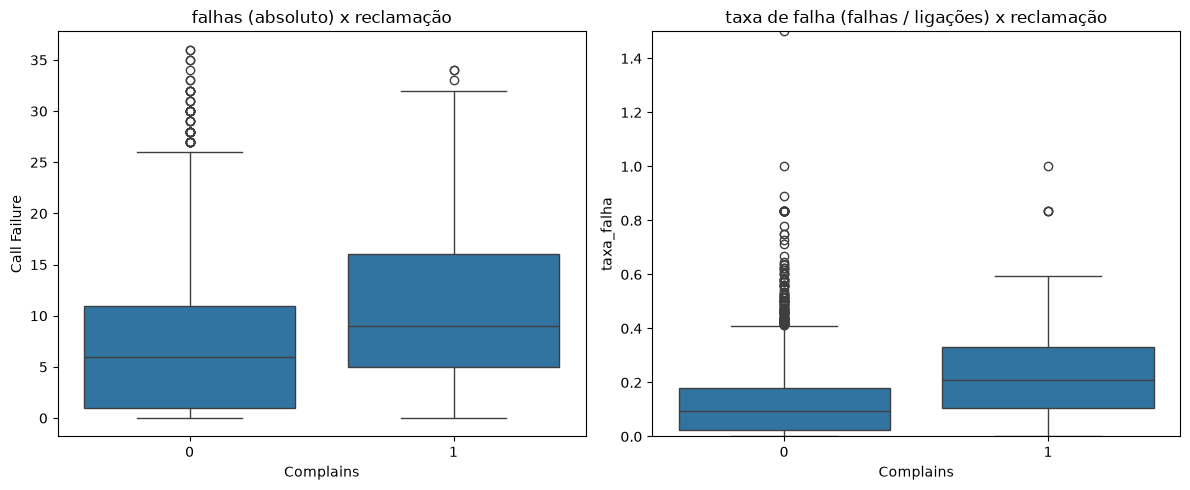

Call Failure        taxa_falha       
                  mean median       mean median
Complains                                      
0                7.478    6.0      0.132  0.093
1               11.500    9.0      0.234  0.208

correlação falhas x reclamação: 0.15
correlação taxa de falha x reclamação: 0.161


In [14]:
dfu['taxa_falha'] = np.where(dfu['Frequency of use'] > 0, dfu['Call Failure'] / dfu['Frequency of use'].replace(0, 1), 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=dfu, x='Complains', y='Call Failure', ax=axes[0]); axes[0].set_title('falhas (absoluto) x reclamação')
sns.boxplot(data=dfu, x='Complains', y='taxa_falha', ax=axes[1]); axes[1].set_title('taxa de falha (falhas / ligações) x reclamação')
axes[1].set_ylim(0, 1.5)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/H3-falhas-x-reclamacao.png', dpi=150, bbox_inches='tight'); plt.show()

display(dfu.groupby('Complains')[['Call Failure', 'taxa_falha']].agg(['mean', 'median']).round(3))
print('correlação falhas x reclamação:', round(dfu['Call Failure'].corr(dfu['Complains']), 3))
print('correlação taxa de falha x reclamação:', round(dfu['taxa_falha'].corr(dfu['Complains']), 3))

**conclusão H3**: a relação existe, mas é **fraca**. quem reclamou tem em média 11,5 falhas (mediana 9) contra 7,5 (mediana 6) de quem não reclamou, e a taxa de falha média sobe de 0,13 para 0,23. a correlação entre falhas e reclamação é de apenas ≈ 0,15, então falhas explicam só uma parte das reclamações. *(a taxa de falha é calculada só para a análise; os clientes sem ligações recebem taxa 0.)*

## H4: como a tupla (falhas, reclamação) se relaciona com o churn?

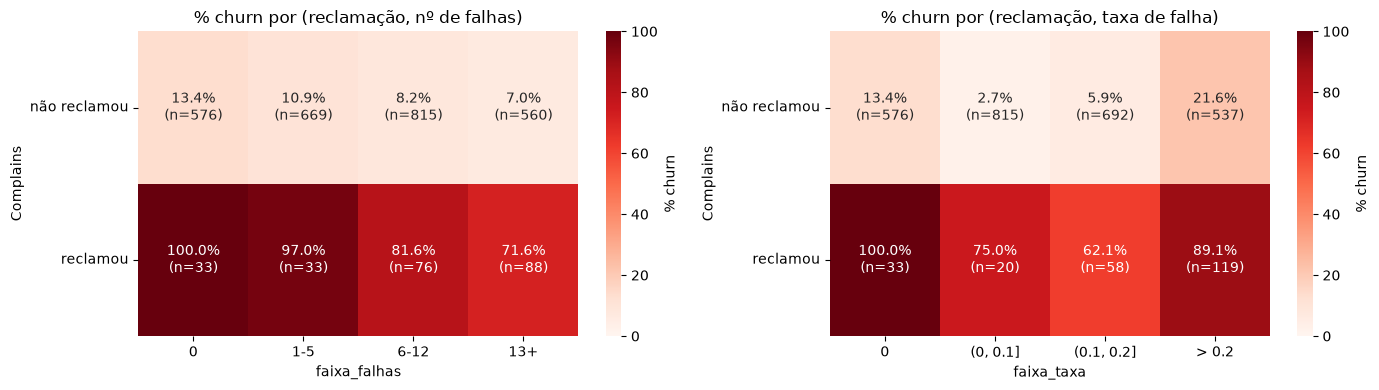

churn só por faixa de falhas:


,n,% churn
faixa_falhas,,
0,609,18.1
1-5,702,15.0
6-12,891,14.5
13+,648,15.7


In [15]:
dfu['faixa_falhas'] = pd.cut(dfu['Call Failure'], [-1, 0, 5, 12, 100], labels=['0', '1-5', '6-12', '13+'])
dfu['faixa_taxa'] = pd.cut(dfu['taxa_falha'], [-0.001, 0, 0.1, 0.2, 100], labels=['0', '(0, 0.1]', '(0.1, 0.2]', '> 0.2'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, tit in [(axes[0], 'faixa_falhas', 'nº de falhas'), (axes[1], 'faixa_taxa', 'taxa de falha')]:
    piv = dfu.pivot_table(index='Complains', columns=col, values='Churn', aggfunc='mean', observed=True) * 100
    n = dfu.pivot_table(index='Complains', columns=col, values='Churn', aggfunc='count', observed=True)
    annot = piv.round(1).astype(str) + '%\n(n=' + n.astype(str) + ')'
    sns.heatmap(piv, annot=annot, fmt='', cmap='Reds', vmin=0, vmax=100, ax=ax, cbar_kws={'label': '% churn'})
    ax.set_title(f'% churn por (reclamação, {tit})'); ax.set_yticklabels(['não reclamou', 'reclamou'], rotation=0)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/H4-churn-por-falhas-e-reclamacao.png', dpi=150, bbox_inches='tight'); plt.show()

print('churn só por faixa de falhas:'); display(taxa_churn(dfu, 'faixa_falhas'))

**conclusão H4**:
- **número absoluto de falhas**: sozinho não separa o churn (entre 14,5% e 18,1% em todas as faixas). dentro de cada grupo de reclamação, o churn chega a **cair** conforme as falhas aumentam (sem reclamação: 13,4% → 7,0%; com reclamação: 100% → 71,6%). provavelmente é porque quem liga mais acumula mais falhas e, como visto em H6, quem usa mais sai menos.
- **taxa de falha**: corrige esse efeito do volume de uso. sem reclamação, o churn vai de 2,7% (taxa até 0,1) para 21,6% (taxa acima de 0,2); com reclamação, de 62,1-75% para 89,1%.
- a combinação **reclamou + taxa de falha alta** é o perfil de maior risco. a reclamação continua sendo o fator dominante.

*a taxa de falha é derivada só para esta análise; incluí-la como atributo nos modelos fica como possível melhoria.*

## H5: o plano de tarifa é decisivo para o churn?

,n,% churn
Tariff Plan,,
1,2621,16.8
2,229,2.6


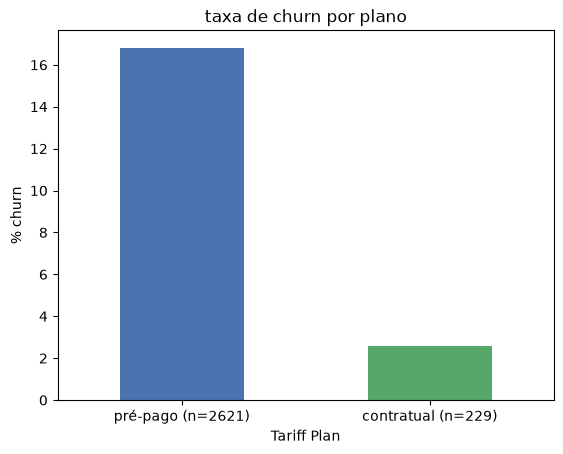

In [16]:
t = taxa_churn(dfu, 'Tariff Plan'); display(t)
ax = t['% churn'].plot(kind='bar', color=['#4C72B0', '#55A868'])
ax.set_xticklabels([f'pré-pago (n={t.n.iloc[0]})', f'contratual (n={t.n.iloc[1]})'], rotation=0)
ax.set_ylabel('% churn'); ax.set_title('taxa de churn por plano'); plt.savefig(f'{FIG_DIR}/H5-churn-por-plano.png', dpi=150, bbox_inches='tight'); plt.show()

**conclusão H5**: o plano contratual tem churn bem menor (2,6% contra 16,8% no pré-pago), mas reúne só 229 dos 2850 clientes (8%). o plano **não é decisivo sozinho**: quase todos os churns (cerca de 440 de 446) estão no pré-pago, onde a taxa é parecida com a média geral. a relação faz sentido, já que um contrato dificulta o cancelamento.

## H6: clientes que cancelam usam o serviço com frequência?

Churn,mediana não churn,mediana churn
Frequency of use,64.00,29.000
Seconds of Use,3596.50,1256.500
Frequency of SMS,26.00,11.000
Distinct Called Numbers,24.00,11.000
Customer Value,271.54,102.565
Subscription Length,35.00,35.000


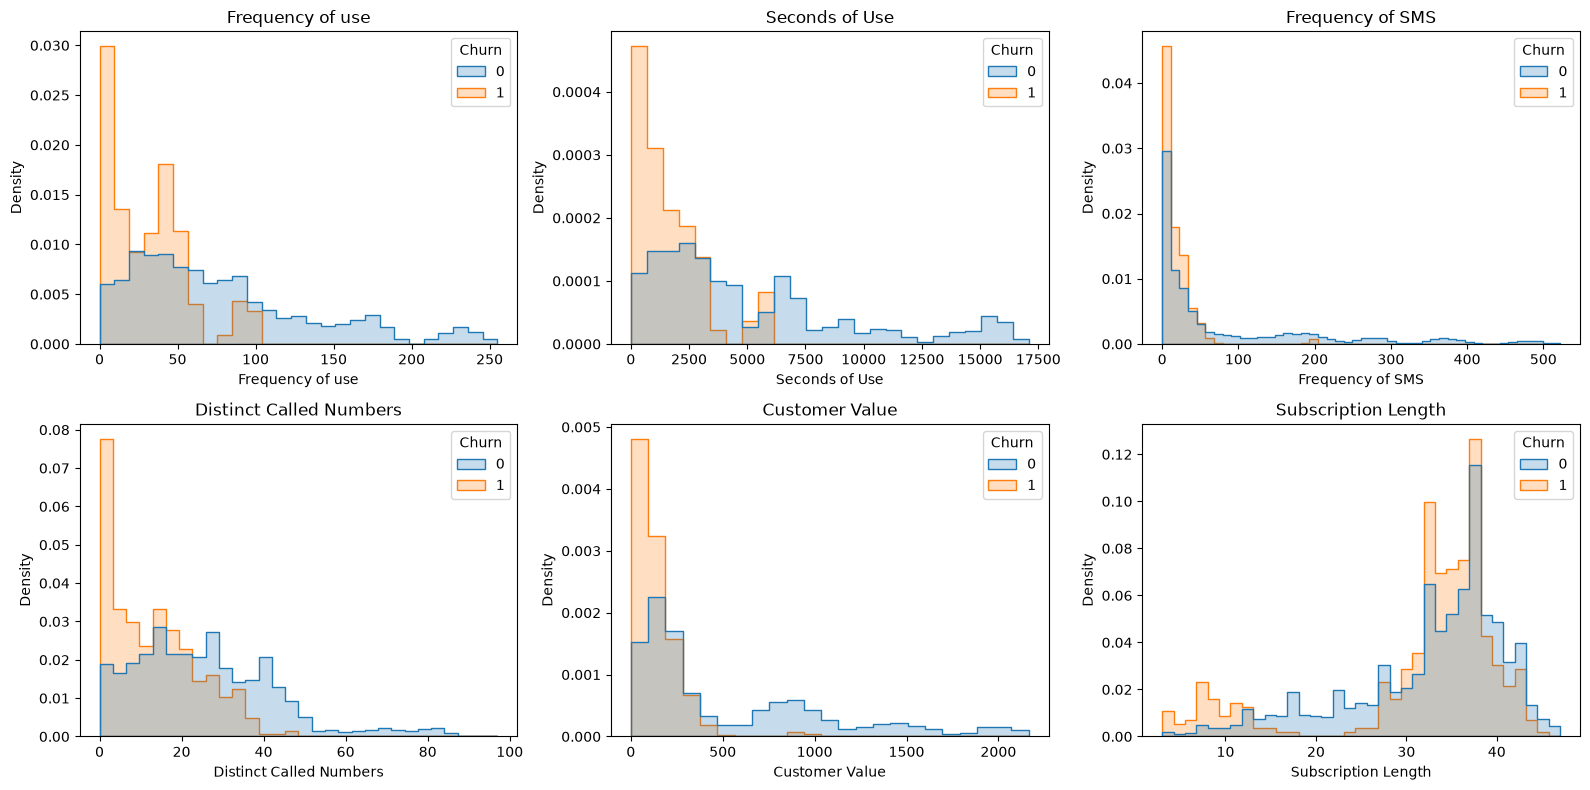

clientes sem nenhum uso: 107 | % churn: 52.3%
clientes com uso:        2743 | % churn: 14.2%


In [17]:
uso = ['Frequency of use', 'Seconds of Use', 'Frequency of SMS', 'Distinct Called Numbers', 'Customer Value', 'Subscription Length']
display(dfu.groupby('Churn')[uso].median().T.rename(columns={0: 'mediana não churn', 1: 'mediana churn'}))

fig, axes = plt.subplots(2, 3, figsize=(16, 8)); axes = axes.ravel()
for ax, c in zip(axes, uso):
    sns.histplot(data=dfu, x=c, hue='Churn', stat='density', common_norm=False, element='step', ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/H6-uso-churn-x-nao-churn.png', dpi=150, bbox_inches='tight'); plt.show()

sem_uso = dfu['Frequency of use'] == 0
print(f'clientes sem nenhum uso: {sem_uso.sum()} | % churn: {dfu.loc[sem_uso, "Churn"].mean():.1%}')
print(f'clientes com uso:        {(~sem_uso).sum()} | % churn: {dfu.loc[~sem_uso, "Churn"].mean():.1%}')

**conclusão H6**: quem cancela usa **muito menos** o serviço. as medianas dos clientes churn ficam entre 35% e 46% das medianas de quem fica: 29 contra 64 ligações, 1.256 contra 3.596 segundos, 11 contra 26 SMS, 11 contra 24 números distintos. o tempo de assinatura é igual (mediana de 35 meses nos dois grupos), então não se trata de clientes recém-chegados. entre os 107 clientes sem nenhum uso, 52,3% saíram.

isso indica que o churn costuma vir antes do cancelamento formal: o cliente vai deixando de usar o serviço. somado a H2 (reclamação), aponta para problemas de pós-venda e suporte. a queda de uso pode servir de alerta precoce para ações de retenção.

In [18]:
dfu = dfu.drop(columns=['taxa_falha', 'faixa_falhas', 'faixa_taxa'])  # colunas auxiliares só da análise